# Date-A-Scientist Machine Learning Project

This project is an exercise in using the OK Cupid dating profile dataset. The goal is to see if variables can be used to predict zodiac sign, a metric judged to be important by users for matching. As these profiles generate a vast amount of data, the platforms use data science methods to improve the likelihood that matches will lead partnership. Utilizing the provided dataset, the data will be investigated and machine learning methods will be used to see if zodiac sign can be predicted.

This project was made by Codecademy and the datasource is stored in `profiles.csv`



In [3]:
# import key libraries for pre-processing and probing data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('profiles.csv')

#print column names to understand what variables might be important
print(df.columns)

Index(['age', 'body_type', 'diet', 'drinks', 'drugs', 'education', 'essay0',
       'essay1', 'essay2', 'essay3', 'essay4', 'essay5', 'essay6', 'essay7',
       'essay8', 'essay9', 'ethnicity', 'height', 'income', 'job',
       'last_online', 'location', 'offspring', 'orientation', 'pets',
       'religion', 'sex', 'sign', 'smokes', 'speaks', 'status'],
      dtype='object')


In [5]:
# obtain information about nulls and data size
print(df.info()) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 31 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   body_type    54650 non-null  object 
 2   diet         35551 non-null  object 
 3   drinks       56961 non-null  object 
 4   drugs        45866 non-null  object 
 5   education    53318 non-null  object 
 6   essay0       54458 non-null  object 
 7   essay1       52374 non-null  object 
 8   essay2       50308 non-null  object 
 9   essay3       48470 non-null  object 
 10  essay4       49409 non-null  object 
 11  essay5       49096 non-null  object 
 12  essay6       46175 non-null  object 
 13  essay7       47495 non-null  object 
 14  essay8       40721 non-null  object 
 15  essay9       47343 non-null  object 
 16  ethnicity    54266 non-null  object 
 17  height       59943 non-null  float64
 18  income       59946 non-null  int64  
 19  job 

In [6]:
#remove essay responses from df as they require NLP for correct digestion

df.drop(df.columns[6:16], axis=1, inplace=True)


In [7]:
#fix misencoded apostrophe 
df['offspring'] = df['offspring'].str.replace("&rsquo;","'")



The following categorical variables had too many unique values for a bar plot: diet (18), education (32), ethnicity (217), job (21), last_online (30123), location (199), religion (45), sign (48), speaks (7647)


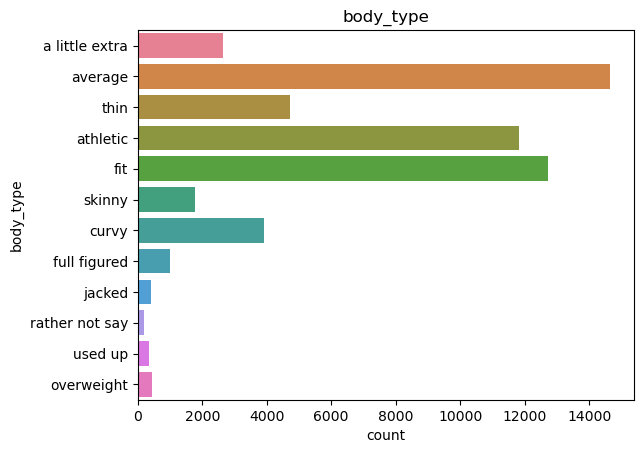

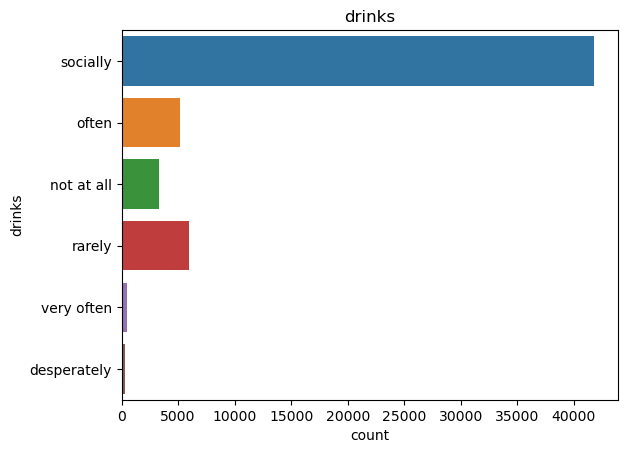

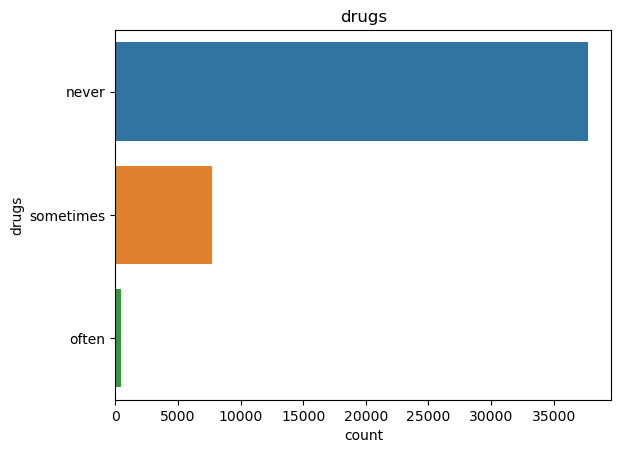

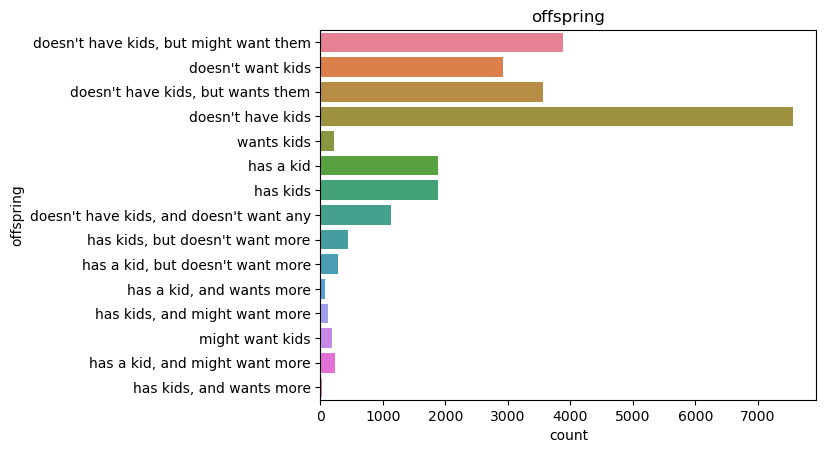

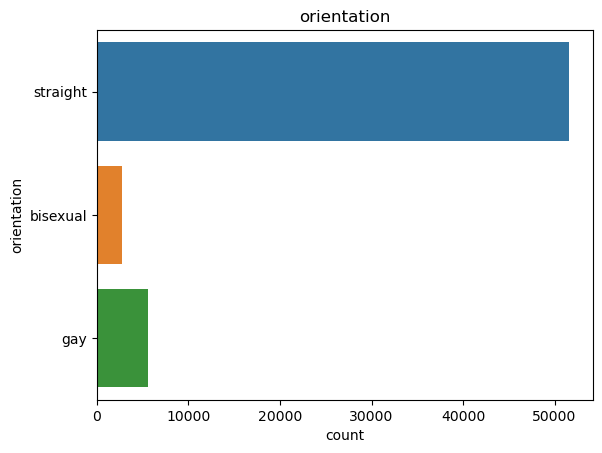

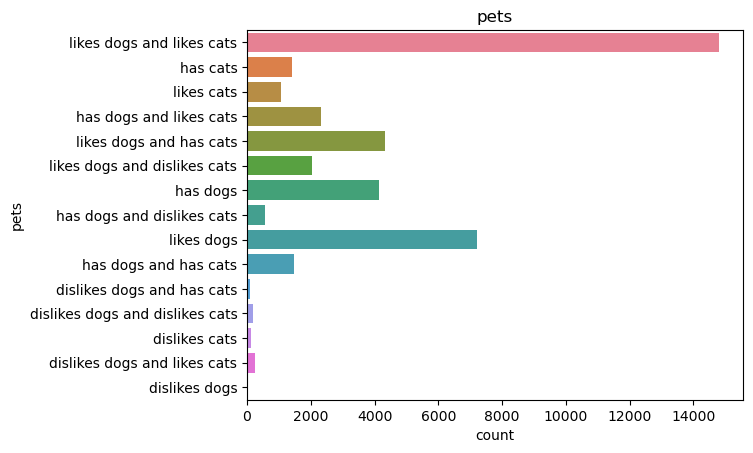

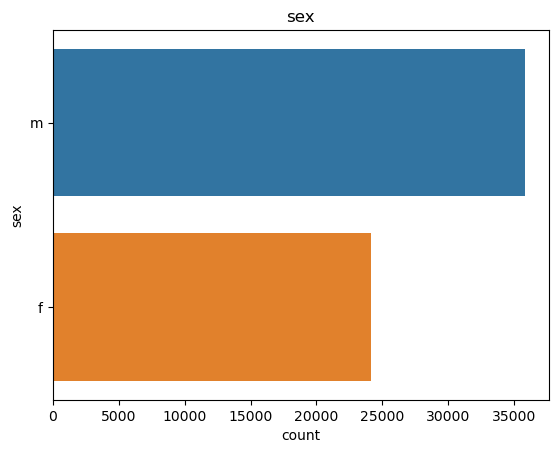

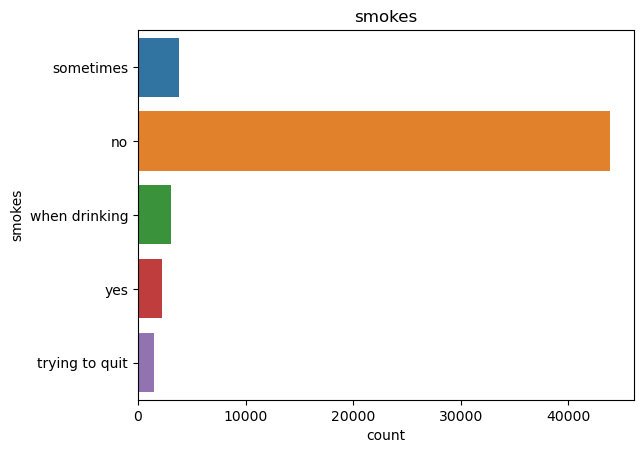

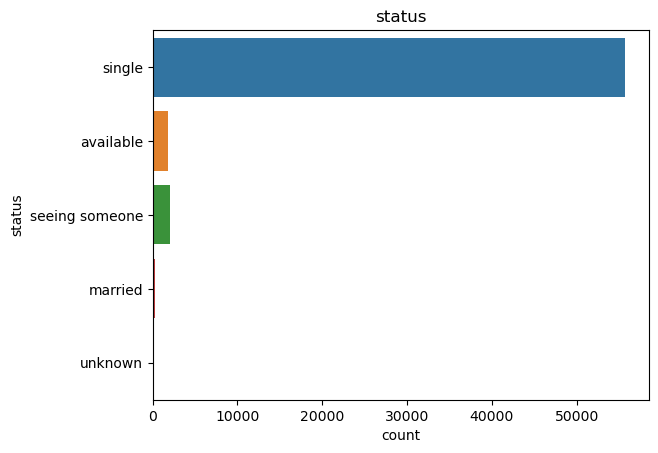

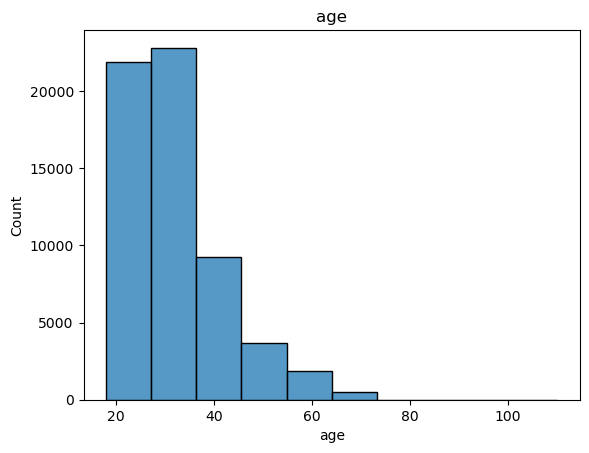

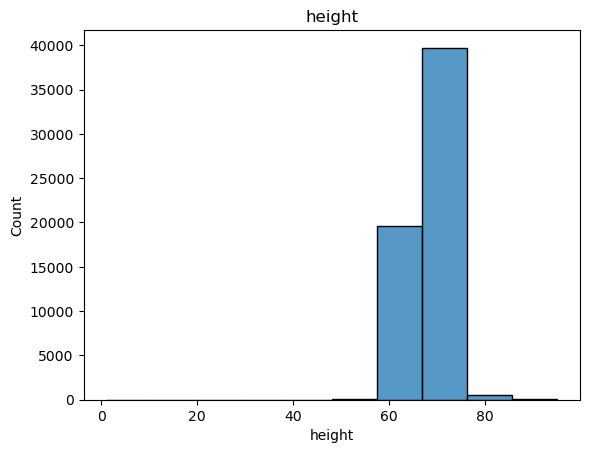

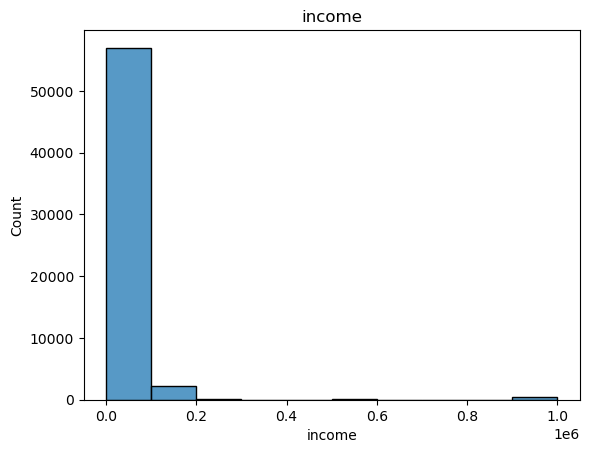

In [8]:
#plot all the columns based on datatype

obj_cols = []
long_obj = []
num_cols = []

for col in df.columns:
    if df[col].dtype == 'object':
        if df[col].nunique() <=15:
            obj_cols.append(col)
        else:
            long_obj.append(col + ' (' + str(df[col].nunique()) + ')') 
            
    elif df[col].dtype == 'int64' or df[col].dtype=='float64':
        num_cols.append(col)
    else:
        print(f'{col} has dtype:{df[col].dtype}')


print(f'The following categorical variables had too many unique values for a bar plot: {", ".join(long_obj)}')

for obj in obj_cols:
    sns.countplot(data = df, y=obj, hue=obj, legend=False)
    plt.title(str(obj))
    plt.tight_layout
    plt.show()

for col in num_cols:
    sns.histplot(data = df, x=col, bins=10, legend=False)
    plt.title(str(col))
    plt.tight_layout
    plt.show()



In [9]:
#determine the range of values in each column as a cursory glance to understand what cleaning and processing may be required
for col in df.columns:
    print(f'{col}:\n{df[col].unique()}')



age:
[ 22  35  38  23  29  32  31  24  37  28  30  39  33  26  27  20  25  40
  36  21  34  43  46  41  42  45  18  55  50  59  44  48  54  51  62  52
  19  58  66  53  63  47  49  61  60  57  56  65  64  68 110  69  67 109]
body_type:
['a little extra' 'average' 'thin' 'athletic' 'fit' nan 'skinny' 'curvy'
 'full figured' 'jacked' 'rather not say' 'used up' 'overweight']
diet:
['strictly anything' 'mostly other' 'anything' 'vegetarian' nan
 'mostly anything' 'mostly vegetarian' 'strictly vegan'
 'strictly vegetarian' 'mostly vegan' 'strictly other' 'mostly halal'
 'other' 'vegan' 'mostly kosher' 'strictly halal' 'halal'
 'strictly kosher' 'kosher']
drinks:
['socially' 'often' 'not at all' 'rarely' nan 'very often' 'desperately']
drugs:
['never' 'sometimes' nan 'often']
education:
['working on college/university' 'working on space camp'
 'graduated from masters program' 'graduated from college/university'
 'working on two-year college' nan 'graduated from high school'
 'working on mast

Seeing the unique outputs for each column allows us to start forumlating interesting questions of the data. Other information gleaned from this lets you see how the data itself is structured. `sign` will need to be recoded as the 12 zodiacs have qualifiers after them in some inputs. Variables regligion, education, pets, and diet will need to be recoded to create a more homogenous range.


In [10]:
#recoding the religion to get how intensely they believe in the religion
#if only the religion was entered, it is assumed they care enough to have it identified and is therefore reclassified as somewhat serious about it
df['relig_int'] = np.where(df['religion'].str.split().str.len() ==1, 
                           'somewhat serious about it',
                           df['religion'].str.split(pat=' ',n=2).str.get(2).str.lstrip())

#recode pets into dogs and cats based on has or likes
df['dogs'] = np.where(df['pets'].str.contains('^likes|has dogs', regex=True), 1, 0)
df['cats'] = np.where(df['pets'].str.contains('^likes|has cats', regex=True), 1, 0)

#gets the dietary preference by only selecting the final element of a split. 
#modifiers would be the first element in the split and if no modifier is present then no split occurs, first element is also last element
df['diet_clean'] = df['diet'].str.split().str.get(-1)



Time to clean the dataset. We will be employing feature engineering and selection methods. The columns to be dropped are ones that are judged to have little impact, they are:
status, speaks, smokes, religion, offspring (due to low non-null), location, last_online, income (many do not report an income),age

In [11]:
df['state'] = df['location'].str.split().str.get(-1)
print(df['state'].unique())

['california' 'colorado' 'york' 'oregon' 'arizona' 'hawaii' 'montana'
 'wisconsin' 'virginia' 'spain' 'nevada' 'illinois' 'vietnam' 'ireland'
 'louisiana' 'michigan' 'texas' 'kingdom' 'massachusetts' 'carolina'
 'idaho' 'mississippi' 'jersey' 'florida' 'minnesota' 'georgia' 'utah'
 'washington' 'connecticut' 'tennessee' 'island' 'columbia' 'canada'
 'missouri' 'germany' 'pennsylvania' 'netherlands' 'switzerland' 'mexico'
 'ohio']


In [32]:
target_cols = ['diet_clean','relig_int', 'drinks','drugs','smokes','orientation','dogs', 'cats','sign']
df_int = df[target_cols]
df_clean = df_int.dropna()
df_clean.info()



<class 'pandas.core.frame.DataFrame'>
Index: 17333 entries, 0 to 59944
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   diet_clean   17333 non-null  object
 1   relig_int    17333 non-null  object
 2   drinks       17333 non-null  object
 3   drugs        17333 non-null  object
 4   smokes       17333 non-null  object
 5   orientation  17333 non-null  object
 6   dogs         17333 non-null  int64 
 7   cats         17333 non-null  int64 
 8   sign         17333 non-null  object
dtypes: int64(2), object(7)
memory usage: 1.3+ MB


In [33]:
#convert input variables into dummies
for col in target_cols[:-3]:
    df_clean = pd.get_dummies(df_clean, columns=[col], prefix=[col], drop_first=True)


need to make sign into usable variables

In [34]:
#create X and Y columns

#remove qualifiers and only take sign
Y = df_clean['sign'].str.split().str.get(0)

#check for class imbalance
print(Y.value_counts())
Y = Y.to_numpy().ravel()
X = df_clean.drop(columns='sign') 

#X.describe(include='all')

sign
gemini         1585
cancer         1539
leo            1514
virgo          1505
taurus         1467
libra          1453
aries          1437
scorpio        1429
sagittarius    1386
pisces         1384
aquarius       1342
capricorn      1292
Name: count, dtype: int64


# Machine Learning

First set will be on basic ML methods to determine level of complexity required. As the dataset is relatively small, computational resources can be used to show the range of ML solutions. 

In [35]:
from sklearn.model_selection import train_test_split, GridSearchCV

#set test size to 20% of data, and fix a random state for repeatability
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.25, random_state=14)



In [36]:
#Using a basic regression first
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression().fit(X_train, Y_train)
lr_pred = lr_model.predict(X_train)


In [37]:
from sklearn.metrics import classification_report, accuracy_score
print(classification_report(Y_train,lr_pred))

              precision    recall  f1-score   support

    aquarius       0.09      0.00      0.00       991
       aries       0.11      0.07      0.08      1068
      cancer       0.10      0.11      0.11      1144
   capricorn       0.17      0.01      0.02       961
      gemini       0.10      0.14      0.12      1180
         leo       0.10      0.18      0.13      1144
       libra       0.10      0.22      0.14      1136
      pisces       0.09      0.03      0.05      1051
 sagittarius       0.11      0.03      0.05      1044
     scorpio       0.09      0.19      0.13      1080
      taurus       0.12      0.02      0.04      1075
       virgo       0.10      0.17      0.13      1125

    accuracy                           0.10     12999
   macro avg       0.11      0.10      0.08     12999
weighted avg       0.11      0.10      0.08     12999



In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, Y_train)
knn_pred = knn.predict(X_train)


print(f'KNN Train Classification Report:\n{classification_report(Y_train,knn_pred)}')

In [20]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier()
tree.fit(X_train,Y_train)
tree_pred = tree.predict(X_train)
tree_test_pred = tree.predict(X_test)

print(f'Decision Tree Train Classification Report:\n{classification_report(Y_train,tree_pred)}')
print(f'Decision Tree Test Classification Report:\n{classification_report(Y_test,tree_test_pred)}')

Decision Tree Train Classification Report:
              precision    recall  f1-score   support

    aquarius       0.46      0.77      0.57       996
       aries       0.47      0.69      0.56      1060
      cancer       0.58      0.68      0.62      1134
   capricorn       0.58      0.63      0.60       919
      gemini       0.60      0.64      0.62      1156
         leo       0.63      0.63      0.63      1127
       libra       0.65      0.57      0.61      1072
      pisces       0.71      0.52      0.60      1006
 sagittarius       0.75      0.53      0.62      1007
     scorpio       0.76      0.52      0.61      1028
      taurus       0.68      0.54      0.60      1061
       virgo       0.67      0.51      0.58      1114

    accuracy                           0.60     12680
   macro avg       0.63      0.60      0.60     12680
weighted avg       0.63      0.60      0.60     12680

Decision Tree Test Classification Report:
              precision    recall  f1-score   su

Tree is extremely overfit, will employ hyperparameter tuning to first determine if it is still the best model. First by finding optimal depth with grid search

In [21]:
param_grid = {'max_depth': list(range(1,32,2))}
grid_search = GridSearchCV(estimator=tree, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train,Y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

best_tree = grid_search.best_estimator_

test_acc = best_tree.score(X_test, Y_test)
print(f'Best tree depth {best_params} with score {best_score.round(4)} had test accuracy {test_acc}')

Best tree depth {'max_depth': 1} with score 0.0911 had test accuracy 0.09022082018927445


Does not appear as if there is an optimal tree depth that can result in good accuaracy. Will utilize ensemble method to try to counter overfitting.

In [22]:
from sklearn.ensemble import RandomForestClassifier

In [23]:
rf = RandomForestClassifier(random_state=14)
rf.fit(X_train, Y_train)
rf_train_pred = rf.predict(X_train)
rf_test_pred = rf.predict(X_test)
print(classification_report(Y_train,rf_train_pred))
print(f'RF accuracy {accuracy_score(Y_test,rf_test_pred)}')


              precision    recall  f1-score   support

    aquarius       0.55      0.63      0.59       996
       aries       0.55      0.59      0.57      1060
      cancer       0.63      0.62      0.62      1134
   capricorn       0.60      0.58      0.59       919
      gemini       0.62      0.60      0.61      1156
         leo       0.70      0.60      0.65      1127
       libra       0.60      0.59      0.60      1072
      pisces       0.59      0.59      0.59      1006
 sagittarius       0.62      0.59      0.61      1007
     scorpio       0.66      0.59      0.62      1028
      taurus       0.55      0.63      0.59      1061
       virgo       0.57      0.61      0.59      1114

    accuracy                           0.60     12680
   macro avg       0.60      0.60      0.60     12680
weighted avg       0.61      0.60      0.60     12680

RF accuracy 0.08201892744479496


Does not overcome overfitting and resulting accuracy issues on test data. 

# Conclusion

Based on the above analysis, simple ML methods cannot be used to predict the sign based on the above reworking of the data. With limited computational power, it is challenging to predict the sign. More advanced methods may have better success.